<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/1_Implement_a_basic_CNN_for_classifying_handwritten_digits.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28)


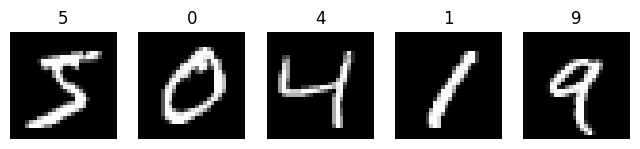

In [ ]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Load data (60,000 train + 10,000 test images of 28x28)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print(x_train.shape, y_train.shape, x_test.shape)

# 2. Preprocess: scale pixels 0-255 -> 0-1, add channel dimension
x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test  = x_test.reshape(-1, 28, 28, 1) / 255.0

# look at a few images
plt.figure(figsize=(8, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1); plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(y_train[i]); plt.axis('off')
plt.show()

In [ ]:
# 3. Build the CNN
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),   # 26x26x32
    layers.MaxPooling2D((2, 2)),                    # 13x13x32
    layers.Conv2D(64, (3, 3), activation='relu'),   # 11x11x64
    layers.MaxPooling2D((2, 2)),                    # 5x5x64
    layers.Flatten(),                               # 1600
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')          # 10 digits
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 4. Compile + train
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 112ms/step - accuracy: 0.9216 - loss: 0.2574 - val_accuracy: 0.9830 - val_loss: 0.0604
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9777 - loss: 0.0731 - val_accuracy: 0.9875 - val_loss: 0.0450
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 108ms/step - accuracy: 0.9833 - loss: 0.0536 - val_accuracy: 0.9887 - val_loss: 0.0388
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 47s 110ms/step - accuracy: 0.9866 - loss: 0.0426 - val_accuracy: 0.9902 - val_loss: 0.0342
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 113ms/step - accuracy: 0.9889 - loss: 0.0356 - val_accuracy: 0.9918 - val_loss: 0.0322


Test accuracy: 99.13%


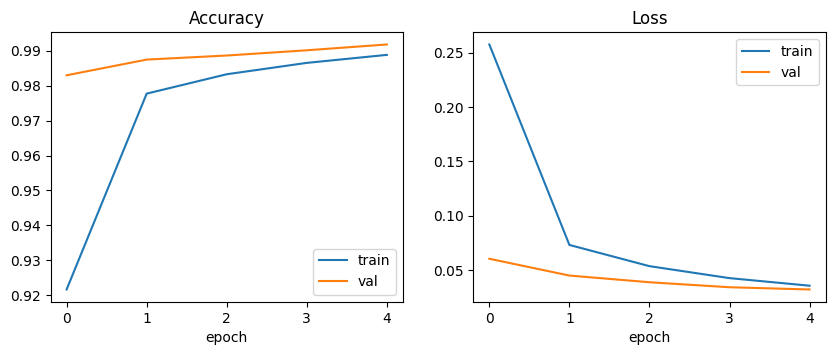

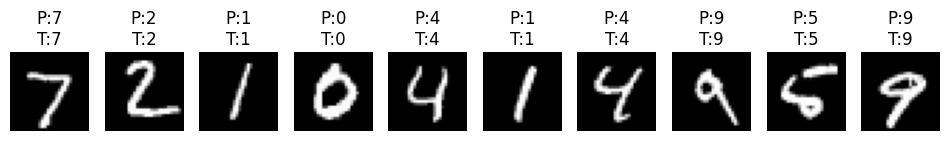

In [ ]:
# 5. Evaluate on unseen test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc*100:.2f}%")     # expect about 99%

# accuracy / loss curves
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2); plt.plot(history.history['loss'], label='train'); plt.plot(history.history['val_loss'], label='val')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.show()

# 6. Predict a few test images
pred = np.argmax(model.predict(x_test[:10], verbose=0), axis=1)
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1); plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    plt.title(f"P:{pred[i]}\nT:{y_test[i]}"); plt.axis('off')
plt.show()

In [ ]:
Problem statement: "Implement a basic CNN for classifying handwritten digits."
1. What is the problem?
We give the computer a picture of a handwritten digit (0 to 9), and it must say which digit it is. The pictures come from the MNIST dataset: 60,000 images to learn from and 10,000 to test on. Each image is 28 × 28 pixels, in black and white.
2. What is the solution?
We use a CNN (Convolutional Neural Network). A normal network treats an image as a flat list of numbers and loses the shape. A CNN looks at small patches of the image, so it can pick up edges and curves, and then whole digits.
The idea in one line for your examiner: "The CNN first finds small patterns like edges, then combines them into shapes, and finally decides which digit it is."
3. TensorFlow and Keras are the tools used to build the neural network. Matplotlib draws the graphs and pictures.
4. Load the data
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x means the images and y means the correct answers (labels). The data is split into a training part and a test part. The model learns from the training part. The test images are kept hidden, so we can check how well it does on new digits.
5. reshape(..., 1) adds the channel dimension. The 1 means grayscale (a colour image would have 3).
/ 255.0 changes pixel values from 0–255 to 0–1. Small numbers make training faster and more stable.
0-255== 256 2^8 , a grayscale image is of 8 bits.
6. Sequential means the layers are stacked one after another, as in the table above.
relu is an activation function. It sets negative values to 0, which helps the network learn complex patterns.
softmax converts the 10 scores into probabilities that add up to 1.
7. model.summary() prints every layer, its output shape and its number of parameters. Total parameters are 225,034.
evaluate: This tests the model on the 10,000 images it has never seen. This is the real accuracy.
8. Predict
pred = np.argmax(model.predict(x_test[:10]), axis=1)

The model gives 10 probabilities per image. argmax picks the position of the highest one, which is the predicted digit.
Test *accuracy of about 98.5–99.2%.*
Two graphs. The accuracy curve goes up and the loss curve goes down. Training and validation curves staying close together means there is no overfitting.
A row of 10 test digits labelled P: (predicted) and T: (true).

####BLOCK ####
          START
            |
            v
      Load MNIST Dataset
      (60,000 train images
       10,000 test images)
            |
            v
       Preprocessing
     Resize / Reshape
      28 × 28 × 1
      Normalize 0-1
            |
            v
        CNN MODEL
            |
            v
      Convolution 2D
       32 Filters
            |
            v
        Max Pooling
            |
            v
      Convolution 2D
       64 Filters
            |
            v
        Max Pooling
            |
            v
          Flatten
            |
            v
       Dense Layer 128
            |
            v
         Dropout
            |
            v
       Dense Layer 10
          Softmax
            |
            v
       Compile Model
            |
            v
       Train Model
            |
            v
      Evaluate Accuracy
            |
            v
       Predict Digits
            |
            v
           STOP


















Questions the examiner may ask
Why a CNN instead of a normal network? A CNN keeps the 2D structure of the image and shares the same filter across the whole image, so it needs fewer parameters and finds shapes better.
What does max pooling do? It reduces the image size and keeps the strongest feature in each 2×2 block. This saves computation and avoids overfitting.
Why divide by 255? It scales pixel values to 0–1, so training is faster and more stable.
What is Dropout? It randomly switches off 30% of neurons during training, so the model can't memorise the training data
Epoch: One complete pass of the model over the entire training dataset. With 5 epochs, the model sees all 60,000 images 5 times.

Batch size: The number of images the model looks at before it updates its weights once. With batch size 128, the model reads 128 images, calculates the error, and adjusts itself. It then repeats this for the next 128, and so on.

Small batch: noisy but frequent updates, slower per epoch, less memory.
Large batch: smoother updates, faster per epoch, needs more memory.
Example: 60,000 images ÷ 128 = about 469 updates per epoch.

Iteration (step): One weight update, which is one batch. Number of iterations per epoch = total images ÷ batch size.

Simple example: you have 1,000 questions to study (the dataset). You study 100 at a time (batch size = 100). After each set you review your mistakes (an iteration). That makes 10 iterations. When you finish all 1,000, one epoch is done.

Learning rate: The size of the step the model takes when it corrects its weights. Too big and it overshoots and never settles. Too small and learning is very slow. Adam's default is 0.001.

Parameter vs hyperparameter: Parameters (weights) are learned by the model. Hyperparameters (epochs, batch size, learning rate, number of layers) are chosen by you.

Learning process terms

Loss: A number that shows how wrong the model's predictions are. Lower is better. Training tries to reduce the loss.

Optimizer (Adam): The method that decides how to change the weights to reduce the loss. Adam adapts the step size for each weight, so it is a good default.

Forward propagation: The input passes through the layers to produce a prediction.

Backpropagation: The error is sent backwards through the network, and each weight is told how much it contributed to the mistake. The weights are then adjusted.

Gradient descent: Moving the weights a small step in the direction that reduces the loss, like walking downhill to the lowest point.

Data splits
Set	         Purpose
Training set	The model learns from this
Validation set	Used during training to check progress and tune settings
Test set	Used once at the end for the final, unbiased accuracy


Overfitting: The model memorises the training data, including its noise, instead of learning the general pattern.

Training accuracy is very high (say 99%), but validation or test accuracy is much lower (say 85%).
Student analogy: a student who memorises last year's paper word for word. They score full marks on that paper but fail when the questions change.
Fixes: Dropout, more data, data augmentation, a smaller model, early stopping.

Underfitting: The model is too simple, or hasn't trained enough, to learn the pattern.

Both training and validation accuracy are low.
Student analogy: a student who barely studied and fails every paper.
Fixes: a bigger model, more epochs, better features, a higher learning rate.

Good fit: Training and validation accuracy are both high and close to each other.

		Training accuracy	Validation accuracy
Underfitting	Low			Low
Good fit	High			High (close to training)
Overfitting	Very high		Much lower

How to spot it on the graph: In overfitting, the training curve keeps rising while the validation curve flattens or falls. That widening gap is the warning sign.

Techniques against overfitting
Dropout: randomly switches off some neurons during training (we used 30%), so the model can't depend on any single neuron.
Data augmentation: creating more training examples by flipping, rotating or zooming images.
Early stopping: stopping training when validation performance stops improving.
Regularisation (L1/L2): adds a penalty for large weights, so the model stays simple.
More data: the most reliable fix.
Layer and function terms

Activation function: A function applied after a layer that adds non-linearity, so the network can learn complex patterns.
For a single neuron with inputs \(x_1, x_2, \dots, x_n\), weights \(w_1, w_2, \dots, w_n\), and bias b, the neuron first computes a weighted sum:
\(z=(x_{1}w_{1}+x_{2}w_{2}+\dots +x_{n}w_{n})+b\)
This value z is then passed through an activation function (such as ReLU or sigmoid) to produce the neuron's output.
• Weights: Sit on the connections between neurons. A larger weight gives an input more influence over the neuron's output, while a negative weight pushes the output in the opposite direction. Geometrically, weights affect the slope or steepness of the decision boundary.
• Biases: Act like the intercept (c in y = mx + c). They shift the activation threshold up or down, allowing a model to fit data that does not pass through the origin.

ReLU: max(0, x). Negative values become 0.
Sigmoid: squashes any value to between 0 and 1.
Tanh: squashes to between -1 and 1.
Softmax: converts scores into probabilities that add up to 1. It is used in the final layer for multi-class problems.

Filter / kernel: A small matrix (like 3×3) that slides over the image to detect a feature such as an edge.

Feature map: The output after a filter has slid over the image. It shows where that feature was found.

Stride: How many pixels the filter moves at each step. Stride 1 moves one pixel at a time. Stride 2 skips pixels and halves the size.

Padding: Adding a border of zeros around the image. 'same' keeps the output size equal to the input. 'valid' means no padding, so the size shrinks.

Pooling: Shrinks the feature map. Max pooling keeps the largest value in each window.

Flatten: Converts a 3D block (height × width × channels) into one long list so it can enter a Dense layer.

Dense (fully connected) layer: Every neuron connects to every neuron in the previous layer. It does the final decision-making.

Evaluation terms

Accuracy: Correct predictions ÷ total predictions.

Confusion matrix: A table of true class against predicted class. The diagonal shows correct predictions, and the other cells show mistakes.

Precision: Of everything the model called "positive", how much was truly positive. TP ÷ (TP + FP).

Recall: Of everything truly positive, how much the model found. TP ÷ (TP + FN).

F1 score: The balance of precision and recall.

(TP = true positive, FP = false positive, FN = false negative.)

